In [1]:
import warnings
warnings.filterwarnings("ignore")

IMPORTING NECESSARY PYTHON LIBRARY

In [2]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt


In [3]:
df=pd.read_csv("AI_Usage_and_Impact_on_Students_and_Professionals.csv")
df.sample(5)

,User_ID,Age,Gender,Country,User_Type,Education_Level,Profession,Monthly_Income,AI_Tool,AI_Purpose,AI_Usage_Hours_Per_Day,Tasks_Performed,Monthly_AI_Cost,Productivity_Score,Accuracy_Rating,Satisfaction_Score,Time_Saved_Hours_Per_Week,Work_or_Study_Hours_Per_Day,Would_Recommend
239,U0065,NaN,male,United Kingdom,Student,Bachelor's,Mechanical Engineering Student,334,ChatGPT,Studying,4.1,"Explaining complex physics concepts, solving d...",20,5.2,3.0,7.0,8.4,5.9,Yes
258,U0270,41,Male,Germany,Professional,Diploma,Softwareentwickler (Software Developer),3795,Copilot,Coding,2.9,Code generation and bug fixing with AI assista...,20,7.8,4.0,6.0,8.4,6.8,Yes
118,U0086,23,Female,Pakistan,Professional,Bachelor's,Content Writer,965,Grammarly,Writing,3.3,Blog post creation using AI writing assistants...,0,6.6,4.0,6.0,7.7,9.6,Yes
108,U0188,27,Male,France,Student,High School,History Student,482,DeepSeek,Research,6,"Literature review and document summarization, ...",0,7.6,5.0,8.0,13.1,6.8,Yes
106,U0083,31,Female,Canada,Professional,Ph.D.,Senior Data Scientist,4815,Microsoft Copilot,Data Analysis,4.9,"Building predictive machine learning models, s...",20,8.6,4.0,8.0,10.7,12.4,NaN


In [4]:
df.shape

(300, 19)

In [5]:
df.columns

Index(['User_ID', 'Age', 'Gender', 'Country', 'User_Type', 'Education_Level',
       'Profession', 'Monthly_Income', 'AI_Tool', 'AI_Purpose',
       'AI_Usage_Hours_Per_Day', 'Tasks_Performed', 'Monthly_AI_Cost',
       'Productivity_Score', 'Accuracy_Rating', 'Satisfaction_Score',
       'Time_Saved_Hours_Per_Week', 'Work_or_Study_Hours_Per_Day',
       'Would_Recommend'],
      dtype='str')

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 19 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   User_ID                      300 non-null    str    
 1   Age                          277 non-null    str    
 2   Gender                       290 non-null    str    
 3   Country                      290 non-null    str    
 4   User_Type                    300 non-null    str    
 5   Education_Level              287 non-null    str    
 6   Profession                   285 non-null    str    
 7   Monthly_Income               290 non-null    str    
 8   AI_Tool                      289 non-null    str    
 9   AI_Purpose                   287 non-null    str    
 10  AI_Usage_Hours_Per_Day       293 non-null    str    
 11  Tasks_Performed              282 non-null    str    
 12  Monthly_AI_Cost              288 non-null    str    
 13  Productivity_Score           28

In [7]:
df=df.drop_duplicates()

In [8]:
df.duplicated().sum()

np.int64(0)

In [9]:
df.isna().sum()

User_ID                         0
Age                            23
Gender                         10
Country                        10
User_Type                       0
Education_Level                12
Profession                     14
Monthly_Income                 10
AI_Tool                        10
AI_Purpose                     13
AI_Usage_Hours_Per_Day          7
Tasks_Performed                17
Monthly_AI_Cost                12
Productivity_Score             14
Accuracy_Rating                14
Satisfaction_Score              7
Time_Saved_Hours_Per_Week      10
Work_or_Study_Hours_Per_Day     9
Would_Recommend                 5
dtype: int64

NOT TRAINIG MODEL SO....

In [10]:
df.drop(columns=['Would_Recommend','User_ID'],inplace=True)

I find removing gender best option as other column can be fill from suitable method but this is different

In [11]:
df.dropna(subset=['Gender','Education_Level','AI_Tool','AI_Purpose','Tasks_Performed','Country','Profession'],inplace=True)

In [12]:
df.shape

(212, 17)

In [13]:
df.info()

<class 'pandas.DataFrame'>
Index: 212 entries, 0 to 299
Data columns (total 17 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   Age                          196 non-null    str    
 1   Gender                       212 non-null    str    
 2   Country                      212 non-null    str    
 3   User_Type                    212 non-null    str    
 4   Education_Level              212 non-null    str    
 5   Profession                   212 non-null    str    
 6   Monthly_Income               205 non-null    str    
 7   AI_Tool                      212 non-null    str    
 8   AI_Purpose                   212 non-null    str    
 9   AI_Usage_Hours_Per_Day       207 non-null    str    
 10  Tasks_Performed              212 non-null    str    
 11  Monthly_AI_Cost              204 non-null    str    
 12  Productivity_Score           204 non-null    float64
 13  Accuracy_Rating              201 non

In [14]:
cols=['Age','Monthly_Income','AI_Usage_Hours_Per_Day','Monthly_AI_Cost','Time_Saved_Hours_Per_Week','Work_or_Study_Hours_Per_Day']
for col in cols:
    df[col] = pd.to_numeric(
        df[col].astype(str).str.replace(r'[^\d.]', '', regex=True),
        errors='coerce'
    )

<Axes: xlabel='Age', ylabel='Density'>

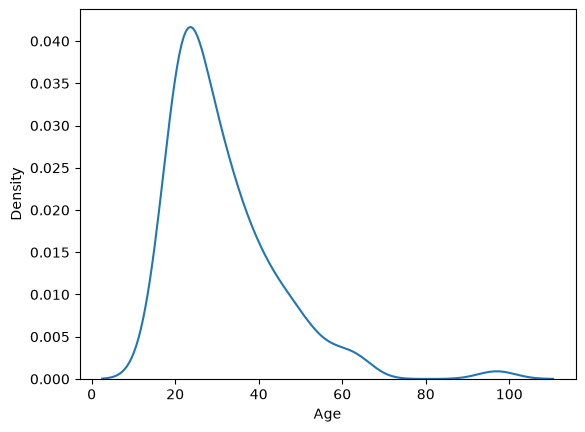

In [15]:
sns.kdeplot(data=df,x='Age')

<Axes: xlabel='Monthly_Income', ylabel='Density'>

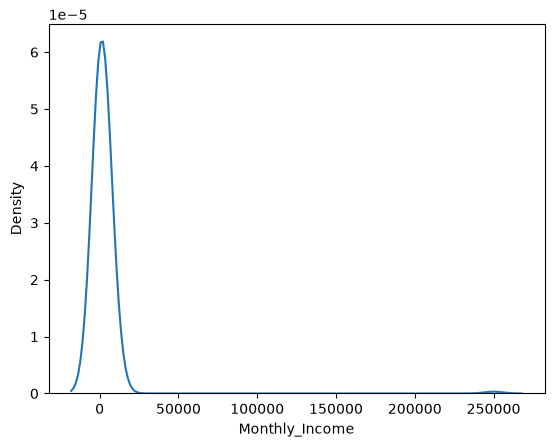

In [16]:
sns.kdeplot(data=df,x='Monthly_Income')

<Axes: xlabel='AI_Usage_Hours_Per_Day', ylabel='Density'>

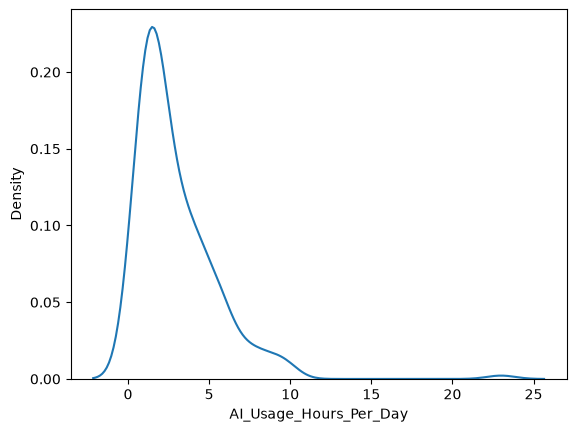

In [17]:
sns.kdeplot(data=df,x='AI_Usage_Hours_Per_Day')

<Axes: xlabel='Monthly_AI_Cost', ylabel='Density'>

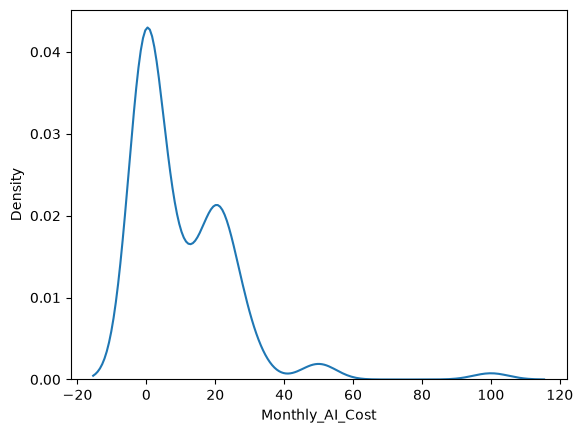

In [18]:
sns.kdeplot(data=df,x='Monthly_AI_Cost')

<Axes: xlabel='Time_Saved_Hours_Per_Week', ylabel='Density'>

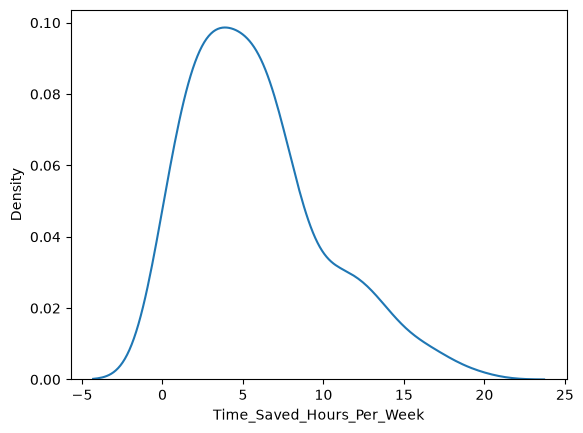

In [19]:
sns.kdeplot(data=df,x='Time_Saved_Hours_Per_Week')

<Axes: xlabel='Work_or_Study_Hours_Per_Day', ylabel='Density'>

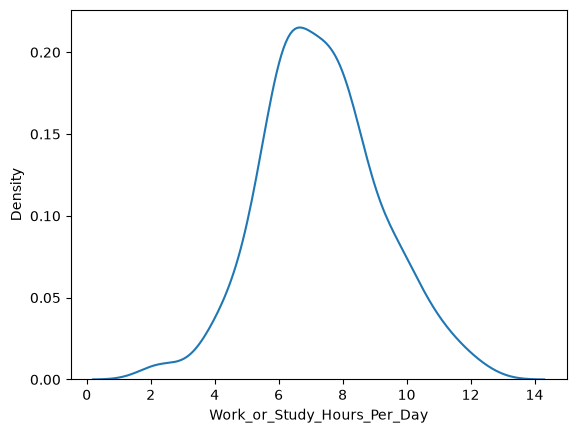

In [20]:
sns.kdeplot(data=df,x='Work_or_Study_Hours_Per_Day')

In [21]:
df['AI_Usage_Hours_Per_Day'].sample(10)

144    1.9
228    6.3
27     0.7
118    3.3
77     2.6
12     0.8
40     1.6
120    3.8
57     7.2
90     0.7
Name: AI_Usage_Hours_Per_Day, dtype: float64

from the distribution above i find that replcaing with median is the best solution here since most columns distribution is skewed

In [22]:
for col in cols:
    df[col]=df[col].fillna(df[col].median())

In [23]:
df.isnull().sum()

Age                             0
Gender                          0
Country                         0
User_Type                       0
Education_Level                 0
Profession                      0
Monthly_Income                  0
AI_Tool                         0
AI_Purpose                      0
AI_Usage_Hours_Per_Day          0
Tasks_Performed                 0
Monthly_AI_Cost                 0
Productivity_Score              8
Accuracy_Rating                11
Satisfaction_Score              6
Time_Saved_Hours_Per_Week       0
Work_or_Study_Hours_Per_Day     0
dtype: int64

<Axes: xlabel='Productivity_Score', ylabel='Density'>

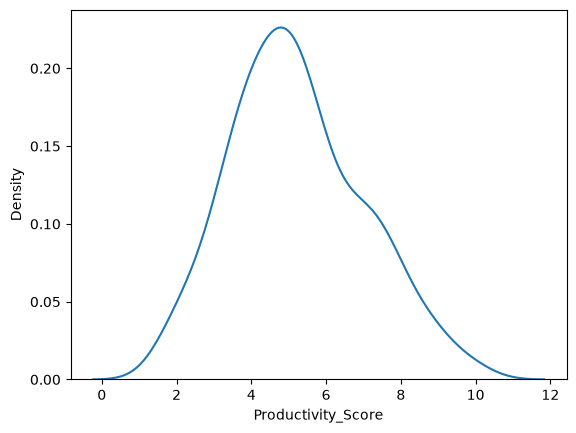

In [24]:
sns.kdeplot(data=df,x='Productivity_Score')

<Axes: xlabel='Accuracy_Rating', ylabel='Density'>

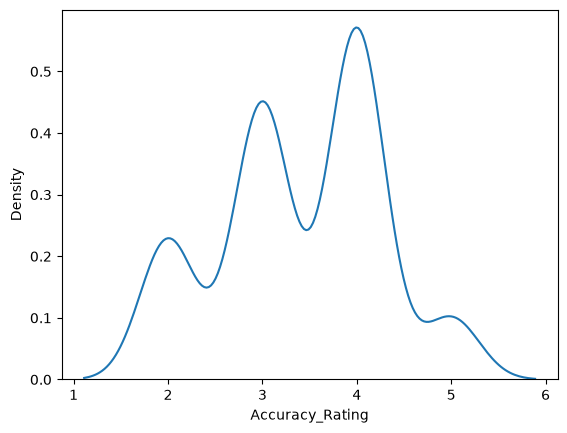

In [25]:
sns.kdeplot(data=df,x='Accuracy_Rating')

<Axes: xlabel='Satisfaction_Score', ylabel='Density'>

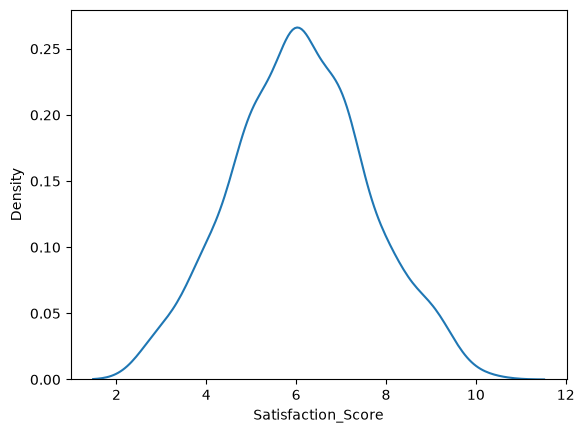

In [26]:
sns.kdeplot(data=df,x='Satisfaction_Score')

adding mean for normally distributed and median for skewed

In [27]:
null_col=['Productivity_Score','Satisfaction_Score']
for col in null_col:
    df[col]=df[col].fillna(df[col].mean())

df['Accuracy_Rating']=df['Accuracy_Rating'].fillna(df['Accuracy_Rating'].median())


In [28]:
df.sample(5)

,Age,Gender,Country,User_Type,Education_Level,Profession,Monthly_Income,AI_Tool,AI_Purpose,AI_Usage_Hours_Per_Day,Tasks_Performed,Monthly_AI_Cost,Productivity_Score,Accuracy_Rating,Satisfaction_Score,Time_Saved_Hours_Per_Week,Work_or_Study_Hours_Per_Day
82,24.0,Male,india,Professional,High School,Data Entry Operator,1761.0,Google Gemini,Data Analysis,0.6,Data cleaning and validation using Python scri...,50.0,3.3,3.0,5.0,4.2,10.5
248,22.0,Female,India,Student,Master's,English Literature Student,167.0,ChatGPT,Writing,8.6,"Essay structuring and outlining, Research pape...",0.0,7.6,3.0,6.0,17.7,5.5
217,63.0,Male,Brazil,Professional,Diploma,Desenvolvedor de Sistemas Junior,1405.0,ChatGPT,Coding,3.4,Escrever código Python e JavaScript com assist...,0.0,6.8,5.0,10.0,7.4,7.5
196,22.0,Male,Australia,Student,Master's,Data Science Student,0.0,Microsoft Copilot,Studying,5.9,"Analyzing research papers with AI summaries, D...",0.0,8.1,3.0,7.0,9.0,7.3
138,29.0,Other,Kenya,Professional,Diploma,Data Analyst,898.0,ChatGPT,Data Analysis,2.3,"Analyzing customer sales trends with Python, g...",0.0,4.5,4.0,5.0,4.9,6.4


I had to drop Tasks_Performed columns as there is different language..I dont know ..extracting meaningful columns would be possible but requires much rows to drop

In [29]:
df.drop(columns=['Tasks_Performed'],inplace=True)

In [30]:
df['Education_Level'].value_counts()

Education_Level
Bachelor's         52
Undergraduate      46
Master's           40
High School        33
Diploma            21
PhD                 8
BA/BSc              2
Masters             2
undergrad           2
Bachelors           2
MA/MSc              1
Ph.D.               1
master's degree     1
HS                  1
Name: count, dtype: int64

In [31]:
df['Profession'].sample(12)

194                                   Psychology Student
92                 Content Strategist & Technical Writer
61                         Business Intelligence Analyst
260                                     Business Analyst
34                        Mechanical Engineering Student
206    Electronics and Communication Engineering Student
234                               Digital Content Writer
74                            English Literature Student
236                                   Statistics Student
118                                       Content Writer
120                           English Literature Student
89                      Senior Machine Learning Engineer
Name: Profession, dtype: str

In [32]:
df['User_Type'].value_counts()

User_Type
Professional    109
Student         103
Name: count, dtype: int64

In [33]:
df['Country'].value_counts()

Country
India                       33
Pakistan                    22
Canada                      22
United States               21
United Kingdom              19
Australia                   17
Brazil                      16
Philippines                 16
Nigeria                     14
Germany                     10
France                       8
Kenya                        3
brazil                       3
canada                       2
france                       1
india                        1
U.K.                         1
United States of America     1
philippines                  1
australia                    1
Name: count, dtype: int64

In [34]:
df['AI_Tool'].value_counts()

AI_Tool
ChatGPT              83
Google Gemini        30
Microsoft Copilot    22
Claude               21
Perplexity AI        16
Grammarly            11
Meta AI               8
DeepSeek              8
chatgpt               4
Chat GPT              2
Chatgpt               2
Gemini                1
gemini                1
Copilot               1
copilot               1
claude                1
Name: count, dtype: int64

In [35]:
df['Gender'].value_counts()

Gender
Male      87
Female    78
M         10
male       8
Other      8
F          8
FEMALE     4
other      3
female     3
MALE       3
Name: count, dtype: int64

In [36]:

# Step 1: basic cleanup (fixes case/whitespace issues like brazil vs Brazil)
for col in ["Education_Level", "Country", "AI_Tool"]:
    df[col] = df[col].astype(str).str.strip().str.lower()

In [37]:
edu_map = {
    "bachelor's": "Bachelor's",
    "bachelors": "Bachelor's",
    "ba/bsc": "Bachelor's",
    "undergraduate": "Bachelor's",
    "undergrad": "Bachelor's",
    "master's": "Master's",
    "masters": "Master's",
    "ma/msc": "Master's",
    "master's degree": "Master's",
    "phd": "PhD",
    "ph.d.": "PhD",
    "high school": "High School",
    "hs": "High School",
    "diploma": "Diploma",
}
df["Education_Level"] = df["Education_Level"].map(edu_map)


country_map = {
    "india": "India",
    "pakistan": "Pakistan",
    "canada": "Canada",
    "united states": "United States",
    "united states of america": "United States",
    "united kingdom": "United Kingdom",
    "u.k.": "United Kingdom",
    "australia": "Australia",
    "brazil": "Brazil",
    "philippines": "Philippines",
    "nigeria": "Nigeria",
    "germany": "Germany",
    "france": "France",
    "kenya": "Kenya",
}
df["Country"] = df["Country"].map(country_map)


tool_map = {
    "chatgpt": "ChatGPT",
    "chat gpt": "ChatGPT",
    "google gemini": "Google Gemini",
    "gemini": "Google Gemini",
    "microsoft copilot": "Microsoft Copilot",
    "copilot": "Microsoft Copilot",
    "claude": "Claude",
    "perplexity ai": "Perplexity AI",
    "grammarly": "Grammarly",
    "meta ai": "Meta AI",
    "deepseek": "DeepSeek",
}
df["AI_Tool"] = df["AI_Tool"].map(tool_map)

In [38]:
print(df[["Education_Level", "Country", "AI_Tool"]].isna().sum())
for col in ["Education_Level", "Country", "AI_Tool"]:
    print(df[col].value_counts(), "\n")
    

Education_Level    0
Country            0
AI_Tool            0
dtype: int64
Education_Level
Bachelor's     104
Master's        44
High School     34
Diploma         21
PhD              9
Name: count, dtype: int64 

Country
India             34
Canada            24
United States     22
Pakistan          22
United Kingdom    20
Brazil            19
Australia         18
Philippines       17
Nigeria           14
Germany           10
France             9
Kenya              3
Name: count, dtype: int64 

AI_Tool
ChatGPT              91
Google Gemini        32
Microsoft Copilot    24
Claude               22
Perplexity AI        16
Grammarly            11
Meta AI               8
DeepSeek              8
Name: count, dtype: int64 

